# 🌱 Computer Vision — Real-World Data Preparation Project
### Session 05 | Student Assignment Notebook

**Project:** Prepare real bean-leaf images for a future CNN model  
**Final goal:** A clean, tested, model-ready image dataset — **no model training today**.

> **Project story:** An AgriTech team wants to build a system that can recognize healthy and diseased bean leaves. Your job is to inspect the real images, test image-processing ideas, and deliver reliable inputs for the ML engineer who will train the CNN.

---

### How to use this notebook

1. Read **Why this step matters** before running the code.
2. Run the starter examples to understand the data.
3. Complete every **🛠️ YOUR TASK** and `TODO` comment. **Do not skip code cells.**
4. Write short answers in **📝 Engineer's notes**. Explain your choice, not just the output.
5. Keep the original dataset unchanged while you experiment.
6. At the end, export your model-ready dataset and run the quality checks.

**Important:** This is a student starter notebook. Some functions intentionally raise `NotImplementedError` until you write your solution. That is part of your task.

## 🎯 Learning goals and project plan

By the end, you will be able to:

- Inspect a real image dataset and find possible quality problems.
- Explain pixels, channels, image shapes, and image data types.
- Convert images between RGB, Grayscale, Binary, and HSV.
- Use masks to select areas with a target color.
- Add *test noise* and compare Mean, Gaussian, and Median filters.
- Apply geometric transformations and explain when they help.
- Build one reusable preprocessing function.
- Keep **train**, **validation**, and **test** data separate and deliver arrays ready for a CNN.

| Stage | Your work | Expected output |
|---|---|---|
| 1 | Load and understand the data | Data overview |
| 2 | Data quality and EDA | Class counts, image examples, audit |
| 3 | Image types | RGB, Grayscale, Binary comparison |
| 4 | Color spaces | HSV channels and green masks |
| 5 | Image histogram | Brightness/contrast interpretation |
| 6 | Noise and filters | Visual and numeric comparison |
| 7 | Geometry and augmentation | Transformation gallery |
| 8 | Build the final preprocessing function | One tested function |
| 9 | Prepare and export the dataset | Arrays + labels + metadata |
| 10 | Quality checks and handoff | Final checklist + short report |

**Working rule:** Test ideas using copies of images. Do not permanently apply experimental noise, binary conversion, or green masks to your final CNN inputs.

## 0 — Setup: Prepare your workspace

### Why this step matters
A real project needs a clear environment, fixed settings, and repeatable results. If the team runs your notebook again, it should produce the same preprocessing steps.

**🛠️ YOUR TASK**
- Open this notebook in Google Colab or Jupyter.
- Run the installation cell once.
- Run the imports and configuration cells.
- Keep the random seed fixed.

In [1]:
# Step 0.1 — Install the required packages.
# In Google Colab, most of these packages may already exist.
%pip install -q datasets opencv-python-headless numpy pandas matplotlib pillow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Step 0.2 — Import tools used during this project.
from datasets import load_dataset
from PIL import Image
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import json

# Set one fixed seed so random examples can be reproduced.
SEED = 42
rng = np.random.default_rng(SEED)

# We will use the same image size for the future CNN.
TARGET_SIZE = (224, 224)  # (width, height) for OpenCV
DATASET_ID = "AI-Lab-Makerere/beans"
EXPORT_DIR = Path("beans_model_ready")
EXPORT_DIR.mkdir(exist_ok=True)

print("OpenCV version:", cv2.__version__)
print("Target image size:", TARGET_SIZE)

c:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


OpenCV version: 5.1.0
Target image size: (224, 224)


## 1 — Load the real dataset

### Why this step matters
Before cleaning any data, you must know **where it comes from**, **what the labels mean**, and **how the dataset is divided**. This protects you from using the wrong data or creating data leakage.

**Dataset:** [Beans dataset — Makerere AI Lab on Hugging Face](https://huggingface.co/datasets/AI-Lab-Makerere/beans). It contains real bean-leaf images in three categories:

- `angular_leaf_spot`
- `bean_rust`
- `healthy`

It already provides `train`, `validation`, and `test` splits. **Keep those splits; do not merge them.** The first download needs internet access and may take a little while.

**🛠️ YOUR TASK**
1. Run the next cell and read the dataset structure.
2. Answer: What is one *feature*? What is a *label*?
3. Record how many images are in each split.

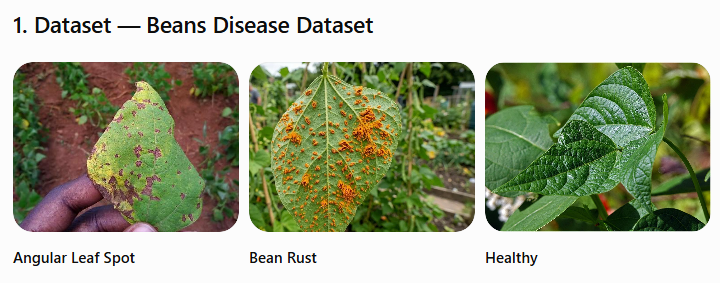

In [3]:
# Step 1.1 — Load the dataset from Hugging Face.
# Note: the internet is needed the first time.
dataset = load_dataset(DATASET_ID)

print(dataset)
print("Available splits:", list(dataset.keys()))

# Read the class names from the dataset metadata, not by guessing.
CLASS_NAMES = dataset["train"].features["labels"].names
CLASS_TO_ID = {name: index for index, name in enumerate(CLASS_NAMES)}
print("Class names:", CLASS_NAMES)
print("Class-to-ID mapping:", CLASS_TO_ID)

DatasetDict({
    train: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 1034
    })
    validation: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 133
    })
    test: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 128
    })
})
Available splits: ['train', 'validation', 'test']
Class names: ['angular_leaf_spot', 'bean_rust', 'healthy']
Class-to-ID mapping: {'angular_leaf_spot': 0, 'bean_rust': 1, 'healthy': 2}


Example fields: dict_keys(['image_file_path', 'image', 'labels'])
Example label ID: 0
Example label name: angular_leaf_spot
Array shape: (500, 500, 3)
Array dtype: uint8


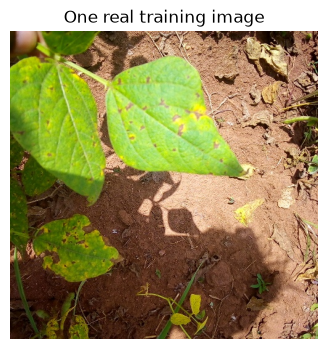

In [4]:
# Step 1.2 — Look at one example.
# Hugging Face image objects are usually decoded to PIL images.
example = dataset["train"][0]
print("Example fields:", example.keys())
print("Example label ID:", example["labels"])
print("Example label name:", CLASS_NAMES[example["labels"]])

# Convert to RGB to make the output predictable.
example_image = np.asarray(example["image"].convert("RGB"))
print("Array shape:", example_image.shape)
print("Array dtype:", example_image.dtype)

plt.figure(figsize=(5, 4))
plt.imshow(example_image)
plt.title("One real training image")
plt.axis("off")
plt.show()

**📝 Engineer's notes — Stage 1**

- **Input features:** Bean leaf photographs (image pixels, represented as RGB values).
- **Target label:** One of the dataset's three classes: healthy, bean_rust, or angular_leaf_spot (use the printed `CLASS_NAMES` order).
- **Number of images in train / validation / test:** 1034 / 133 / 128.
- **Why must we keep the test set separate?** It is held out for a final unbiased evaluation; using it to make development decisions causes data leakage.

**Checkpoint:** One row represents one bean-leaf image and its integer class label.

## 2 — Explore and audit the data (EDA)

### Why this step matters
A CNN cannot fix a broken dataset by itself. Before preprocessing, we need to know:

- Are some classes much larger than others?
- Do images have different sizes?
- Do we have unreadable images or unexpected image modes?
- Are labels clear and correctly mapped?

We will **inspect first**, then decide what processing is needed.

### Step 2.1 — Check class balance

**🛠️ YOUR TASK**

1. Count each class in each split.
2. Make a bar chart showing the class count in the **training** split.
3. Write a short observation: Is the training data balanced? Why does that matter?

**Hint:** `Counter(...)`, `CLASS_NAMES`, `plt.bar(...)`.

,split,class_name,count
0,train,angular_leaf_spot,345
1,train,bean_rust,348
2,train,healthy,341
3,validation,angular_leaf_spot,44
4,validation,bean_rust,45
5,validation,healthy,44
6,test,angular_leaf_spot,43
7,test,bean_rust,43
8,test,healthy,42


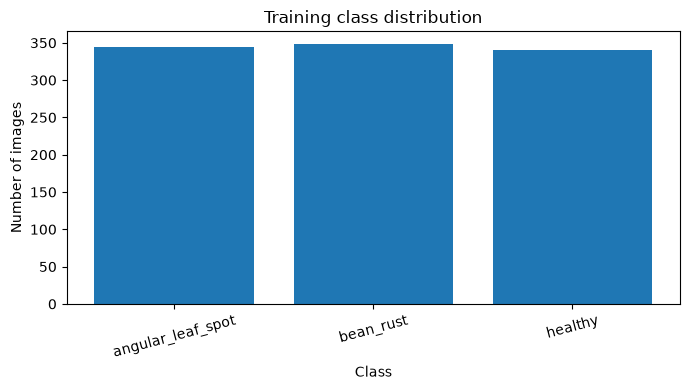

Training counts: {'angular_leaf_spot': 345, 'bean_rust': 348, 'healthy': 341}
Balanced? Approximately balanced


In [5]:
# Starter: create a small class-count table.
class_count_rows = []
for split_name, split_data in dataset.items():
    counts = Counter(split_data["labels"])
    for class_id, class_name in enumerate(CLASS_NAMES):
        class_count_rows.append({
            "split": split_name,
            "class_name": class_name,
            "count": counts.get(class_id, 0),
        })

class_count_df = pd.DataFrame(class_count_rows)
display(class_count_df)

# TODO 2.1 — Make a bar chart using the TRAIN rows only.
# Hint 1: train_counts = class_count_df[class_count_df["split"] == "train"]
# Hint 2: use plt.bar(train_counts["class_name"], train_counts["count"])
# Hint 3: add a title, axis labels, and readable class labels.
train_counts = class_count_df[class_count_df["split"] == "train"]
plt.figure(figsize=(7, 4))
plt.bar(train_counts["class_name"], train_counts["count"])
plt.title("Training class distribution")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
print("Training counts:", dict(zip(train_counts["class_name"], train_counts["count"])))
print("Balanced?", "Approximately balanced" if train_counts["count"].max() / train_counts["count"].min() < 1.5 else "Not perfectly balanced; consider class-aware evaluation.")


### Step 2.2 — Create an image gallery

### Why this step matters
Numbers do not show everything. A visual gallery helps us notice image quality, background changes, leaf position, and lighting conditions.

**🛠️ YOUR TASK**
- Show **9 random training images** in a 3×3 grid.
- Write each image's class name above it.
- Look for at least **two differences** between real images.

**Hint:** `rng.choice(...)`, `plt.subplots(3, 3)`, `axes.flat`, `imshow(...)`.

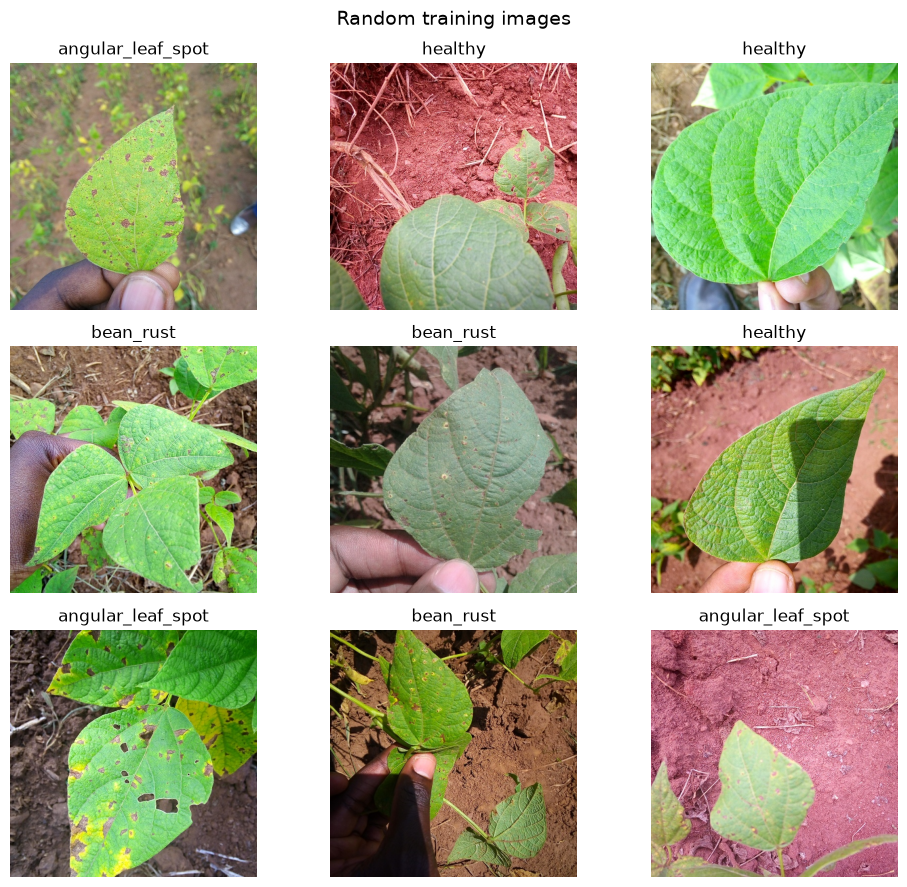

In [6]:
# Show 9 reproducible random training examples.
random_indices = rng.choice(len(dataset["train"]), size=9, replace=False)
fig, axes = plt.subplots(3, 3, figsize=(10, 9))
for axis, row_index in zip(axes.flat, random_indices):
    item = dataset["train"][int(row_index)]
    image_array = np.asarray(item["image"].convert("RGB"))
    axis.imshow(image_array)
    axis.set_title(CLASS_NAMES[int(item["labels"])])
    axis.axis("off")
plt.suptitle("Random training images", fontsize=14)
plt.tight_layout()
plt.show()


### Step 2.3 — Inspect image sizes, channels, and modes

### Why this step matters
A batch of CNN inputs must have a consistent shape. Some image files might be RGB, grayscale, RGBA, or different sizes. We should **measure this before resizing**.

**🛠️ YOUR TASK**
- Review the table below.
- Report the minimum and maximum width and height.
- Check if there are images that are not RGB.
- Explain what can go wrong if we stack different image sizes directly.

,split,index,width,height,mode,label
0,train,0,500,500,RGB,angular_leaf_spot
1,train,1,500,500,RGB,angular_leaf_spot
2,train,2,500,500,RGB,angular_leaf_spot
3,train,3,500,500,RGB,angular_leaf_spot
4,train,4,500,500,RGB,angular_leaf_spot



Image size summary:
         width  height
count  1295.0  1295.0
mean    500.0   500.0
std       0.0     0.0
min     500.0   500.0
25%     500.0   500.0
50%     500.0   500.0
75%     500.0   500.0
max     500.0   500.0

Image mode counts:
 mode
RGB    1295
Name: count, dtype: int64


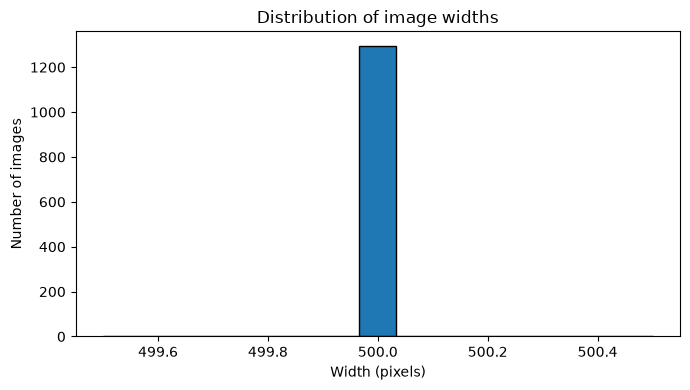

Width range: 500 to 500
Height range: 500 to 500


In [7]:
# This is a data audit, so it is OK to scan all split metadata.
image_audit = []
for split_name, split_data in dataset.items():
    for image_index, row in enumerate(split_data):
        pil_img = row["image"]
        image_audit.append({
            "split": split_name,
            "index": image_index,
            "width": pil_img.width,
            "height": pil_img.height,
            "mode": pil_img.mode,
            "label": CLASS_NAMES[int(row["labels"])],
        })

audit_df = pd.DataFrame(image_audit)
display(audit_df.head())
print("\nImage size summary:\n", audit_df[["width", "height"]].describe())
print("\nImage mode counts:\n", audit_df["mode"].value_counts())

# TODO 2.3 — Plot image widths OR heights as a histogram.
# Hint: plt.hist(audit_df["width"], bins=15)
plt.figure(figsize=(7, 4))
plt.hist(audit_df["width"], bins=15, edgecolor="black")
plt.title("Distribution of image widths")
plt.xlabel("Width (pixels)")
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()
print("Width range:", audit_df["width"].min(), "to", audit_df["width"].max())
print("Height range:", audit_df["height"].min(), "to", audit_df["height"].max())


### Step 2.4 — Find unreadable or invalid images

### Why this step matters
If one file is broken, your full preprocessing job may stop in the middle. A reliable engineering pipeline checks input quality and records problems.

**🛠️ YOUR TASK**
- Try to decode every image.
- Find empty images or unexpected arrays.
- Keep a list of issues (split, row, error).
- Do not silently delete a bad image. Explain the decision.

**Hint:** `try/except`, `np.asarray(...)`, `array.size`, `np.isfinite(...)`.

In [8]:
# Build an input-integrity checker.
def audit_split_images(split_data, split_name):
    """Return a list of problems found while checking images."""
    issues = []
    for index in range(len(split_data)):
        try:
            image = split_data[index]["image"].convert("RGB")
            array = np.asarray(image)
            if array.size == 0:
                issues.append({"split": split_name, "index": index, "error": "Empty image"})
            elif array.ndim != 3 or array.shape[2] != 3:
                issues.append({"split": split_name, "index": index, "error": f"Unexpected shape: {array.shape}"})
            elif not np.isfinite(array).all():
                issues.append({"split": split_name, "index": index, "error": "Non-finite pixel values"})
        except Exception as error:
            issues.append({"split": split_name, "index": index, "error": str(error)})
    return issues

all_issues = []
for split_name in dataset.keys():
    all_issues.extend(audit_split_images(dataset[split_name], split_name))
print("Number of issues:", len(all_issues))
display(pd.DataFrame(all_issues).head() if all_issues else pd.DataFrame(columns=["split", "index", "error"]))


Number of issues: 0


,split,index,error


**📝 Engineer's notes — Stage 2**

- **Class distribution:** Use the class-count table and training bar chart above. Compare counts rather than assuming the classes are perfectly balanced.
- **Image sizes / modes:** The audit table and summaries above report the observed width, height, and PIL modes; RGB conversion in preprocessing makes channel count consistent.
- **Data quality issues found:** The integrity checker reports the exact number and location of unreadable, empty, invalid, or non-finite images. If the count is zero, record “No issues found.”
- **One risk for the future CNN:** Inconsistent image dimensions or color modes can break batching or create inconsistent model inputs.

**Checkpoint:** Data quality is checked before preprocessing.

## 3 — Understand image types: RGB, Grayscale, Binary

### Why this step matters
Images are numbers. Different image types hold different information:

- **RGB:** Three color channels. Often useful for recognizing plant diseases.
- **Grayscale:** One intensity channel. Useful for understanding shapes, edges, and brightness.
- **Binary:** Two possible states. Useful for simple masks and threshold-based segmentation.

**Important:** For our final CNN, we plan to keep **RGB**. The following conversions are learning experiments, **not** final training-data replacements.

### Step 3.1 — Inspect one RGB pixel

**🛠️ YOUR TASK**
- Select a training image.
- Print its shape and one pixel's RGB values.
- Find its minimum and maximum pixel values.
- Explain what the three values represent.

In [9]:
# Use the same sample to compare the image types.
selected_row = dataset["train"][15]
rgb_image = np.asarray(selected_row["image"].convert("RGB"))

print("RGB shape:", rgb_image.shape)
print("RGB dtype:", rgb_image.dtype)
print("Top-left pixel:", rgb_image[0, 0])

# TODO 3.1 — Print the min and max pixel values.
# TODO 3.1 — Print the Red, Green, Blue values of one pixel separately.
print("Minimum pixel value:", int(rgb_image.min()))
print("Maximum pixel value:", int(rgb_image.max()))
red, green, blue = (int(v) for v in rgb_image[0, 0])
print("Top-left Red:", red, "Green:", green, "Blue:", blue)


RGB shape: (500, 500, 3)
RGB dtype: uint8
Top-left pixel: [127 145  23]
Minimum pixel value: 0
Maximum pixel value: 255
Top-left Red: 127 Green: 145 Blue: 23


### Step 3.2 — Convert RGB to Grayscale

### Why this step matters
Grayscale removes color channels and keeps brightness information. It makes some image-processing algorithms simpler, but it also removes information that may be helpful to the CNN.

**🛠️ YOUR TASK**
- Convert the RGB image to Grayscale.
- Print its new shape.
- Plot RGB and Grayscale images next to each other.

**Hint:** `cv2.COLOR_RGB2GRAY` (do **not** use `COLOR_BGR2GRAY` here, because your NumPy image is RGB).

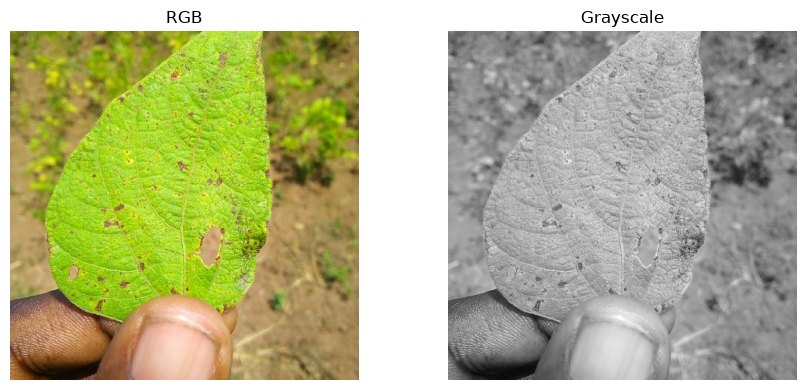

Grayscale shape: (500, 500)


In [10]:
# Convert RGB to grayscale.
gray_image = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2GRAY)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(rgb_image); axes[0].set_title("RGB")
axes[1].imshow(gray_image, cmap="gray", vmin=0, vmax=255); axes[1].set_title("Grayscale")
for axis in axes: axis.axis("off")
plt.tight_layout(); plt.show()
print("Grayscale shape:", gray_image.shape)


### Step 3.3 — Convert Grayscale to Binary

### Why this step matters
Thresholding is a simple way to separate bright and dark parts. It produces a binary result. This does **not** automatically identify sick leaves; it only checks a value against a threshold.

**🛠️ YOUR TASK**
- Use a threshold of **127**.
- Show Original RGB, Grayscale, and Binary in one row.
- Try a second threshold, such as **180**.
- Explain what changed.

**Hint:** `cv2.threshold(gray_image, threshold, 255, cv2.THRESH_BINARY)`.

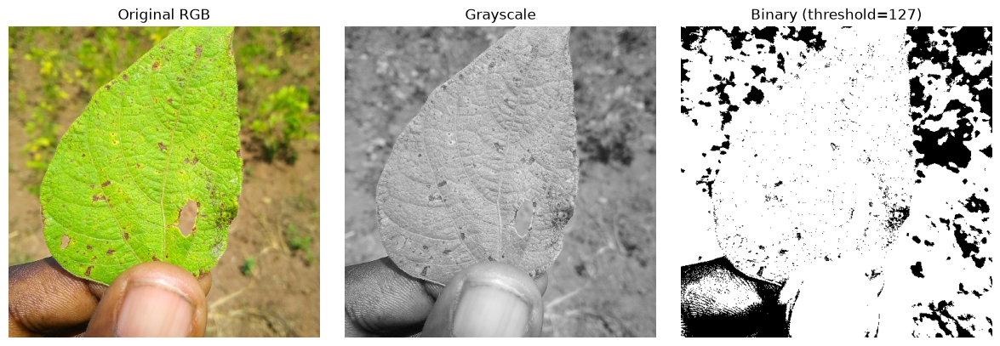

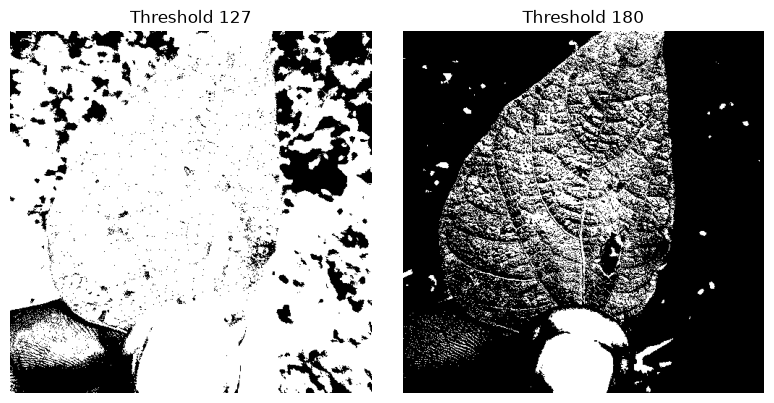

At threshold 180, fewer pixels are white because a higher brightness is required.
White indicates intensity > threshold, not a healthy leaf.


In [11]:
# Threshold grayscale at 127 and 180.
threshold_value = 127
_, binary_image = cv2.threshold(gray_image, threshold_value, 255, cv2.THRESH_BINARY)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(rgb_image); axes[0].set_title("Original RGB")
axes[1].imshow(gray_image, cmap="gray", vmin=0, vmax=255); axes[1].set_title("Grayscale")
axes[2].imshow(binary_image, cmap="gray", vmin=0, vmax=255); axes[2].set_title("Binary (threshold=127)")
for axis in axes: axis.axis("off")
plt.tight_layout(); plt.show()

threshold_value_180 = 180
_, binary_image_180 = cv2.threshold(gray_image, threshold_value_180, 255, cv2.THRESH_BINARY)
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(binary_image, cmap="gray", vmin=0, vmax=255); axes[0].set_title("Threshold 127")
axes[1].imshow(binary_image_180, cmap="gray", vmin=0, vmax=255); axes[1].set_title("Threshold 180")
for axis in axes: axis.axis("off")
plt.tight_layout(); plt.show()
print("At threshold 180, fewer pixels are white because a higher brightness is required.")
print("White indicates intensity > threshold, not a healthy leaf.")


**📝 Engineer's notes — Stage 3**

- **What information is lost after converting RGB to Grayscale?** Hue and color differences are removed; only brightness/intensity remains.
- **What does a white pixel mean in your Binary output?** Its grayscale intensity is greater than the chosen threshold (127 or 180); it does not mean healthy.
- **Which image type should we keep for the final plant disease CNN? Why?** RGB, because color can be an important disease cue and the project contract requires three RGB channels.

## 4 — Explore color spaces: RGB and HSV

### Why this step matters
RGB stores colors using red, green, and blue intensities. HSV separates **Hue** (color family), **Saturation** (color purity), and **Value** (brightness). This can make color selection easier.

For 8-bit images, OpenCV's standard HSV format commonly uses:

| Channel | Range |
|---|---|
| H | 0–179 |
| S | 0–255 |
| V | 0–255 |

**Critical detail:** `cv2.cvtColor` needs the correct input color order. Our array is **RGB**, so use `COLOR_RGB2HSV`.

### Step 4.1 — Convert and inspect HSV channels

**🛠️ YOUR TASK**
- Convert an RGB bean image to HSV.
- Extract H, S, and V channels.
- Show the original RGB image and the three channels in a 2×2 grid.
- Print the value range in each channel.

HSV shape: (500, 500, 3)


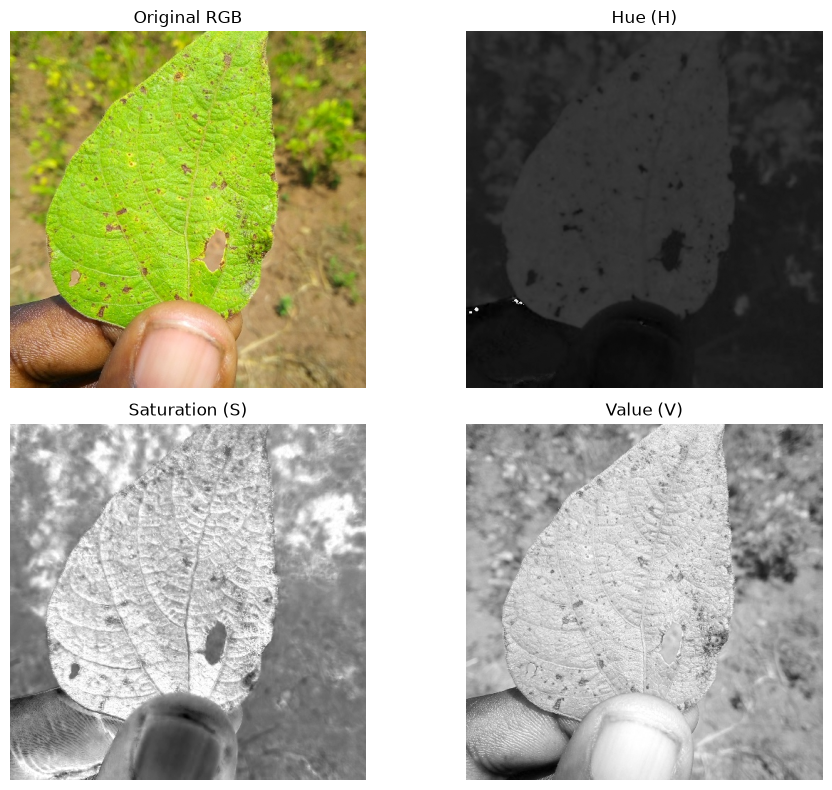

H range: 0 to 179
S range: 2 to 255
V range: 10 to 255


In [12]:
# One line is provided so you can focus on channel analysis.
hsv_image = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2HSV)
print("HSV shape:", hsv_image.shape)

# TODO 4.1 — Extract H, S, V channels using hsv_image[:, :, channel_index].
# TODO 4.1 — Plot the RGB image and the H, S, V channels.
# Hint: display single channels with cmap="gray" and add clear titles.
# TODO 4.1 — Print min/max for each of the three channels.
h_channel, s_channel, v_channel = [hsv_image[:, :, i] for i in range(3)]
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes[0, 0].imshow(rgb_image); axes[0, 0].set_title("Original RGB")
for axis, channel, title in zip(axes.flat[1:], [h_channel, s_channel, v_channel], ["Hue (H)", "Saturation (S)", "Value (V)"]):
    axis.imshow(channel, cmap="gray"); axis.set_title(title)
for axis in axes.flat: axis.axis("off")
plt.tight_layout(); plt.show()
for name, channel in [("H", h_channel), ("S", s_channel), ("V", v_channel)]:
    print(f"{name} range: {int(channel.min())} to {int(channel.max())}")


### Step 4.2 — Create a green color mask

### Why this step matters
We can ask: "Which pixels look green?" A mask shows pixels inside a chosen color range. This is useful for understanding color segmentation, but a green region is **not** the same as a healthy leaf.

**🛠️ YOUR TASK**
1. Choose a reasonable lower and upper HSV range for green.
2. Make a binary mask using `cv2.inRange`.
3. Apply the mask to the RGB image using `cv2.bitwise_and`.
4. Show **Original / Mask / Masked RGB** side by side.
5. Adjust the limits if the mask includes too much background.

**Hint:** Start by experimenting with an H range near **35–85**, then choose S and V limits from **0–255**. These are starting points, not universal truth.

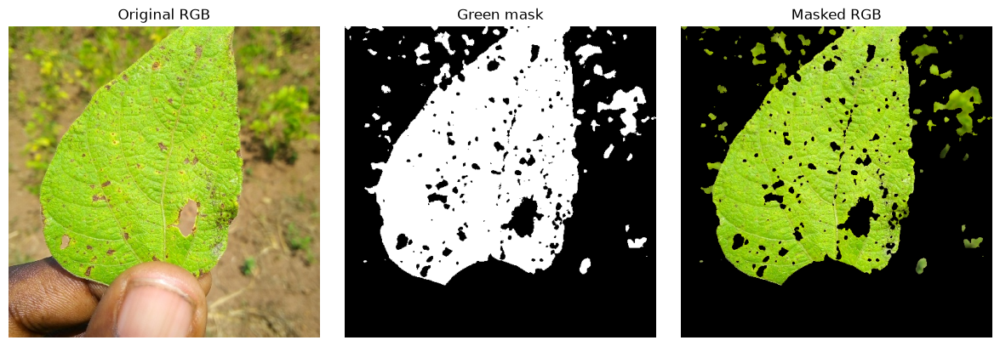

Pixels selected by green mask: 38.84%


In [13]:
# Green HSV range for OpenCV: H=35..85, S=50..255, V=40..255.
lower_green = np.array([35, 50, 40], dtype=np.uint8)
upper_green = np.array([85, 255, 255], dtype=np.uint8)
mask = cv2.inRange(hsv_image, lower_green, upper_green)
masked_rgb = cv2.bitwise_and(rgb_image, rgb_image, mask=mask)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(rgb_image); axes[0].set_title("Original RGB")
axes[1].imshow(mask, cmap="gray"); axes[1].set_title("Green mask")
axes[2].imshow(masked_rgb); axes[2].set_title("Masked RGB")
for axis in axes: axis.axis("off")
plt.tight_layout(); plt.show()
selected_percentage = np.mean(mask > 0) * 100
print(f"Pixels selected by green mask: {selected_percentage:.2f}%")


### Step 4.3 — Compare green masks across classes

**🛠️ YOUR TASK**
- Choose one image from **healthy**, one from **bean_rust**, and one from **angular_leaf_spot**.
- Apply the **same HSV bounds** to all three images.
- Make a comparison chart.
- Answer: Can a green mask alone tell us the disease class? What is its limitation?

**Hint:** Use `CLASS_TO_ID` to find examples from each class; use `next(...)` or filter indices.

Found class examples: ['angular_leaf_spot', 'bean_rust', 'healthy']


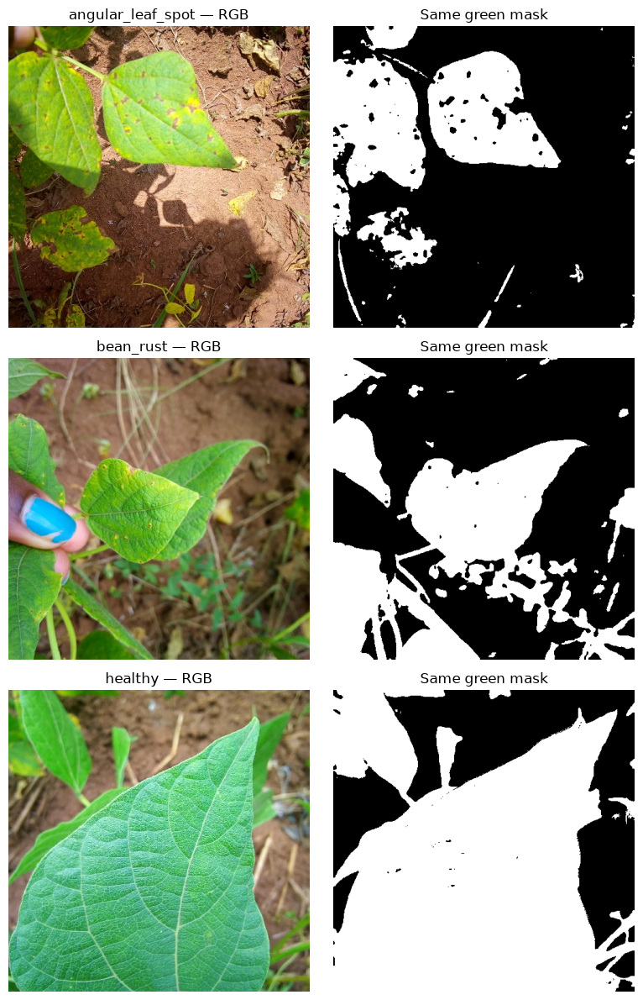

A green mask alone cannot identify disease class: disease symptoms may be spots, lesions, and texture changes, and lighting/backgrounds also affect color.


In [14]:
# Compare one training image from each class with the same green HSV bounds.
class_examples = {}
for row in dataset["train"]:
    label_id = int(row["labels"])
    if label_id not in class_examples:
        class_examples[label_id] = row
    if len(class_examples) == len(CLASS_NAMES):
        break

print("Found class examples:", [CLASS_NAMES[i] for i in class_examples])
fig, axes = plt.subplots(len(class_examples), 2, figsize=(8, 4 * len(class_examples)))
if len(class_examples) == 1:
    axes = np.array([axes])
for row_index, (label_id, row) in enumerate(sorted(class_examples.items())):
    sample_rgb = np.asarray(row["image"].convert("RGB"))
    sample_hsv = cv2.cvtColor(sample_rgb, cv2.COLOR_RGB2HSV)
    sample_mask = cv2.inRange(sample_hsv, lower_green, upper_green)
    axes[row_index, 0].imshow(sample_rgb); axes[row_index, 0].set_title(CLASS_NAMES[label_id] + " — RGB")
    axes[row_index, 1].imshow(sample_mask, cmap="gray"); axes[row_index, 1].set_title("Same green mask")
    axes[row_index, 0].axis("off"); axes[row_index, 1].axis("off")
plt.tight_layout(); plt.show()
print("A green mask alone cannot identify disease class: disease symptoms may be spots, lesions, and texture changes, and lighting/backgrounds also affect color.")


**📝 Engineer's notes — Stage 4**

- **My green HSV range:** Lower `[35, 50, 40]`, upper `[85, 255, 255]` (OpenCV HSV).
- **Why did I choose this range?** It is a reasonable starting interval for green hues while excluding very low saturation and very dark pixels; it should be visually checked on the sample images.
- **One reason a color mask may fail:** Lighting, shadows, backgrounds, and disease discoloration can cause non-leaf pixels to be selected or green leaf pixels to be missed.
- **Should the final CNN receive the mask or the RGB image? Explain.** RGB, because the mask discards useful color, texture, and lesion information; the mask is only an exploratory segmentation aid.

## 6 — Test noise and filters (controlled experiment)

### Why this step matters
Real photos may contain sensor noise, compression artifacts, or poor lighting. Filters can reduce noise, but can also remove disease details. In this experiment, you will **add known noise to a copy** and measure how well each filter recovers the clean image.

**Safety rule for the dataset:** This is an experiment only. **Do not replace the original data with noisy or filtered images** in the final dataset unless you have tested and justified it.

### Step 6.1 — Create two noisy copies

**🛠️ YOUR TASK**

1. Write `add_gaussian_noise(image, sigma, seed)`.
2. Write `add_salt_pepper_noise(image, amount, seed)`.
3. Show clean, Gaussian-noisy, and Salt-and-Pepper-noisy versions side by side.

**Hint for Gaussian:** sample random values with `rng.normal(...)`, add to a **float** copy, clip to `[0,255]`, convert back to `uint8`.

**Hint for Salt-and-Pepper:** choose random pixel positions; set some to black (`0`) and some to white (`255`). If your image has three channels, set all three values for each selected pixel.

Keep the functions reusable — they should work with any RGB image.

In [15]:
# Reproducible noise functions that never modify the input.
def add_gaussian_noise(image, sigma=20, seed=42):
    image = np.asarray(image)
    if image.dtype != np.uint8 or image.ndim != 3 or image.shape[2] != 3:
        raise ValueError("image must be an RGB uint8 array with shape (H, W, 3)")
    local_rng = np.random.default_rng(seed)
    noise = local_rng.normal(0, sigma, image.shape)
    noisy = np.clip(image.astype(np.float32) + noise, 0, 255)
    return noisy.astype(np.uint8)

def add_salt_pepper_noise(image, amount=0.03, seed=42):
    image = np.asarray(image)
    if image.dtype != np.uint8 or image.ndim != 3 or image.shape[2] != 3:
        raise ValueError("image must be an RGB uint8 array with shape (H, W, 3)")
    if not 0 <= amount <= 1:
        raise ValueError("amount must be between 0 and 1")
    local_rng = np.random.default_rng(seed)
    noisy = image.copy()
    height, width = image.shape[:2]
    number = int(amount * height * width)
    indices = local_rng.choice(height * width, size=number, replace=False)
    split = number // 2
    pepper = indices[:split]
    salt = indices[split:]
    noisy.reshape(-1, 3)[pepper] = 0
    noisy.reshape(-1, 3)[salt] = 255
    return noisy


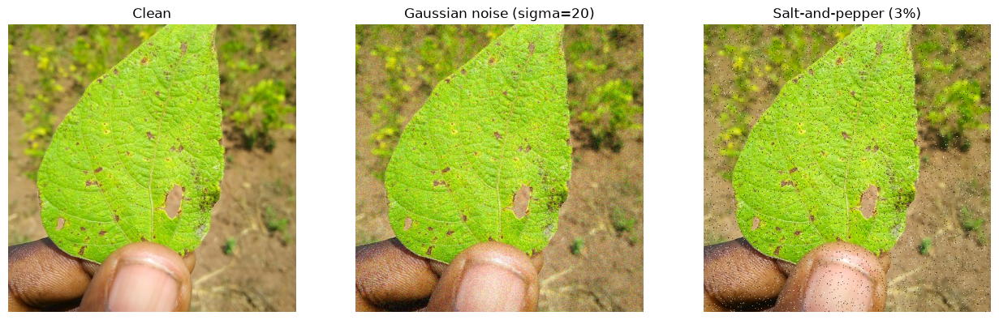

In [16]:
# Generate and display clean and noisy images.
clean_rgb = rgb_image.copy()
gaussian_noisy = add_gaussian_noise(clean_rgb, sigma=20, seed=SEED)
salt_pepper_noisy = add_salt_pepper_noise(clean_rgb, amount=0.03, seed=SEED)
assert np.array_equal(clean_rgb, rgb_image), "You changed the original image!"
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for axis, image, title in zip(axes, [clean_rgb, gaussian_noisy, salt_pepper_noisy],
                              ["Clean", "Gaussian noise (sigma=20)", "Salt-and-pepper (3%)"]):
    axis.imshow(image); axis.set_title(title); axis.axis("off")
plt.tight_layout(); plt.show()


### Step 6.2 — Apply three filters

### Why this step matters
Different noise types may need different filters:

- **Mean:** averages nearby pixels.
- **Gaussian:** weighted average of nearby pixels.
- **Median:** chooses the middle value and is often effective for salt-and-pepper noise.

**🛠️ YOUR TASK**

- Apply all three filters to **both noisy images**.
- Use a **5×5** kernel size (or another size if you explain why).
- Show a comparison table or a 2×4 image gallery: noisy image + three filtered results for each noise type.

**Hints:** `cv2.blur`, `cv2.GaussianBlur`, `cv2.medianBlur`.

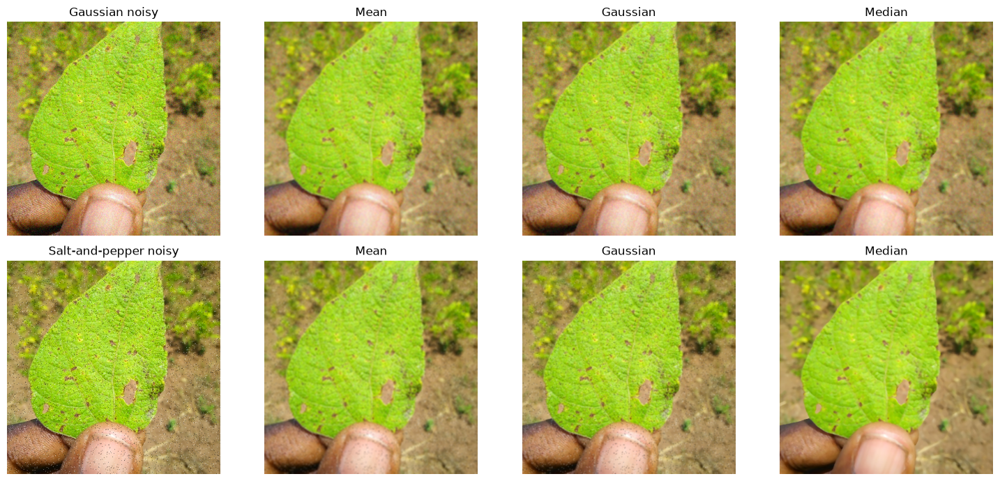

In [17]:
# Apply mean, Gaussian, and median filters.
def apply_three_filters(noisy_image):
    return {
        "Mean": cv2.blur(noisy_image, (5, 5)),
        "Gaussian": cv2.GaussianBlur(noisy_image, (5, 5), 0),
        "Median": cv2.medianBlur(noisy_image, 5),
    }

gaussian_results = apply_three_filters(gaussian_noisy)
salt_pepper_results = apply_three_filters(salt_pepper_noisy)
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for row_axis, noisy, results, noise_name in [
    (axes[0], gaussian_noisy, gaussian_results, "Gaussian"),
    (axes[1], salt_pepper_noisy, salt_pepper_results, "Salt-and-pepper"),
]:
    row_axis[0].imshow(noisy); row_axis[0].set_title(noise_name + " noisy")
    for axis, (filter_name, result) in zip(row_axis[1:], results.items()):
        axis.imshow(result); axis.set_title(filter_name)
    for axis in row_axis: axis.axis("off")
plt.tight_layout(); plt.show()


### Step 6.3 — Compare filters using a metric

### Why this step matters
"This picture looks cleaner" is a useful observation, but engineering decisions also need measurements. Because we created noisy images from a clean original, we can compare outputs to that original.

**MSE (Mean Squared Error):** smaller means closer pixel values to the clean original. It is **not** a perfect measure of visual quality, so also inspect the pictures.

**🛠️ YOUR TASK**
- Compute MSE for both noisy images and all filtered versions.
- Build a small DataFrame with the results.
- Find which filter has the lowest MSE for each noise type.
- Explain any case where a low MSE result still looks blurry.

In [18]:
# This metric helper is provided. You will use it to evaluate your choices.
def mean_squared_error(reference, candidate):
    assert reference.shape == candidate.shape, "Images must have the same shape"
    reference = reference.astype(np.float32)
    candidate = candidate.astype(np.float32)
    return float(np.mean((reference - candidate) ** 2))

# TODO 6.3 — Create a results list:
# rows = []
# rows.append({"Noise type": "Gaussian", "Filter": "No filter", "MSE": ...})
# for filter_name, result in gaussian_results.items(): ...
# Repeat for salt_pepper_results, convert the list to pd.DataFrame.
# Sort by noise type and MSE to compare the choices.
rows = []
for noise_name, noisy, results in [
    ("Gaussian", gaussian_noisy, gaussian_results),
    ("Salt-and-Pepper", salt_pepper_noisy, salt_pepper_results),
]:
    rows.append({"Noise type": noise_name, "Filter": "No filter", "MSE": mean_squared_error(clean_rgb, noisy)})
    for filter_name, result in results.items():
        rows.append({"Noise type": noise_name, "Filter": filter_name, "MSE": mean_squared_error(clean_rgb, result)})
mse_df = pd.DataFrame(rows).sort_values(["Noise type", "MSE"]).reset_index(drop=True)
display(mse_df)
print("Best filter per noise type:")
display(mse_df.loc[mse_df.groupby("Noise type")["MSE"].idxmin()])


,Noise type,Filter,MSE
0,Gaussian,Gaussian,136.894180
1,Gaussian,Mean,170.010208
2,Gaussian,Median,177.817169
3,Gaussian,No filter,382.560760
4,Salt-and-Pepper,Median,149.623962
5,Salt-and-Pepper,Gaussian,155.939713
6,Salt-and-Pepper,Mean,180.972931
7,Salt-and-Pepper,No filter,607.798950


Best filter per noise type:


,Noise type,Filter,MSE
0,Gaussian,Gaussian,136.894180
4,Salt-and-Pepper,Median,149.623962


**📝 Engineer's notes — Stage 6**

- **Best filter for the Gaussian noise test:** Use the lowest-MSE row in the printed Gaussian section of `mse_df`; Gaussian or mean smoothing often performs well, but the measured result is the evidence.
- **Best filter for the Salt-and-Pepper test:** Use the lowest-MSE row in the printed Salt-and-Pepper section; the median filter is commonly effective for impulse noise.
- **Did any filter blur small leaf details?** Smoothing filters can blur edges and small disease spots, especially with a 5×5 kernel.
- **Should we always filter the final dataset?** No. Filtering can remove useful disease details; apply it only if validation evidence shows a benefit.

## 7 — Geometric transformations and safe augmentation

### Why this step matters
Real leaves may appear at different positions, sizes, and angles. Transformations help us understand these changes and may help a future CNN generalize.

**Important difference:**

- **Required preprocessing** makes image dimensions and data types consistent.
- **Data augmentation** creates useful variations of **training** samples. It must **not** create artificial new validation or test images.

**🛠️ YOUR TASK**
- Resize an image to `224×224`.
- Rotate it by `+20°`.
- Move it by `30` pixels to the right and `15` pixels down.
- Apply horizontal flip.
- Show original + four results.
- Explain when a transformation may cut off part of a leaf.

**Hints:** `cv2.resize`, `cv2.getRotationMatrix2D`, `cv2.warpAffine`, `cv2.flip`.

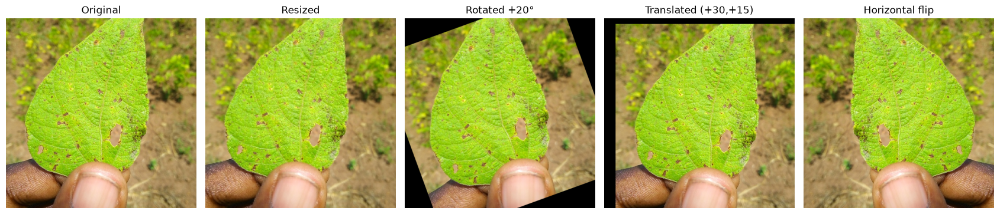

Rotation/translation/cropping can cut off a leaf when it touches or extends beyond the image boundary.


In [19]:
# Create resized, rotated, translated, and flipped versions.
def make_transformations(image):
    height, width = image.shape[:2]
    resized = cv2.resize(image, TARGET_SIZE)
    center = (width / 2, height / 2)
    rotation_matrix = cv2.getRotationMatrix2D(center, 20, 1.0)
    rotated = cv2.warpAffine(image, rotation_matrix, (width, height))
    translation_matrix = np.float32([[1, 0, 30], [0, 1, 15]])
    translated = cv2.warpAffine(image, translation_matrix, (width, height))
    flipped = cv2.flip(image, 1)
    return {"Resized": resized, "Rotated +20°": rotated, "Translated (+30,+15)": translated, "Horizontal flip": flipped}

transformations = make_transformations(clean_rgb)
fig, axes = plt.subplots(1, 5, figsize=(17, 4))
axes[0].imshow(clean_rgb); axes[0].set_title("Original")
for axis, (name, transformed) in zip(axes[1:], transformations.items()):
    axis.imshow(transformed); axis.set_title(name)
for axis in axes: axis.axis("off")
plt.tight_layout(); plt.show()
print("Rotation/translation/cropping can cut off a leaf when it touches or extends beyond the image boundary.")


### Step 7.2 — Small augmentation plan

| Possible change | Use in TRAIN augmentation? | Explain why |
|---|---|---|
| Small rotation | Yes | Leaves can be photographed at different angles; keep the angle modest to avoid excessive cropping. |
| Horizontal flip | Yes, if orientation is not class-defining | It can increase viewpoint variation while preserving most leaf features. |
| Brightness change | Maybe | Mild changes model lighting variation; extreme changes may hide symptoms. |
| Very strong blur | No | It can erase small spots, edges, and disease texture. |
| Random crop removing most of leaf | No | It removes the main object and may discard the evidence needed for classification. |

Apply augmentation to TRAIN only, never to validation or test.

## 8 — Design the final preprocessing pipeline

### Why this step matters
The next engineer should not repeat all your experiments manually. You need **one reliable function** that gives the future CNN predictable inputs.

### Final design contract

For every input PIL or NumPy image, your function should return:

| Property | Requirement |
|---|---|
| Color order | RGB |
| Shape | `(224, 224, 3)` |
| Data type | `np.float32` |
| Pixel range | `0.0` to `1.0` |
| Labels | Not changed by the image function |
| Random changes | None in validation/test; none in the saved base arrays |

**Why these choices?**
- **RGB:** disease signs may depend on color.
- **Same size:** we can stack images into batches.
- **float32:** a common numeric format for deep learning.
- **Normalization:** stable input scale. A pretrained model may require different preprocessing later.
- **No experimental filter by default:** we have not proved that it improves accuracy.

**Design note:** Direct resizing may stretch an image with a different aspect ratio. Inspect your images first, and explain whether direct resize or a padding strategy is suitable.

### Step 8.1 — Write your reusable function

**🛠️ YOUR TASK**

Implement `preprocess_image(image)` following these steps:

1. Validate that the input is an image.
2. Convert to RGB (avoid OpenCV's BGR/RGB confusion).
3. Resize to target size.
4. Convert pixel values to `float32`.
5. Normalize to `[0, 1]`.
6. Return the new array. **Do not change the original image.**

**Hints:** `PIL.Image.convert('RGB')`, `np.asarray`, `cv2.cvtColor` *only when needed*, `cv2.resize`, `.astype(np.float32) / 255.0`.

In [20]:
# Reusable model preprocessing: accepts PIL or RGB NumPy input.
def preprocess_image(image, target_size=TARGET_SIZE):
    """Return RGB float32 image (height, width, 3) normalized to [0,1].

    NumPy inputs must already be RGB (not BGR). Input is never modified.
    target_size is (width, height).
    """
    if isinstance(image, Image.Image):
        rgb = np.asarray(image.convert("RGB"))
    elif isinstance(image, np.ndarray):
        if image.size == 0:
            raise ValueError("Input image is empty")
        if image.ndim == 2:
            rgb = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
        elif image.ndim == 3 and image.shape[2] == 3:
            rgb = image.copy()
        elif image.ndim == 3 and image.shape[2] == 4:
            rgb = cv2.cvtColor(image, cv2.COLOR_RGBA2RGB)
        else:
            raise ValueError(f"Unsupported NumPy image shape: {image.shape}")
    else:
        raise TypeError("image must be a PIL Image or NumPy array")
    if rgb.dtype != np.uint8:
        if not np.issubdtype(rgb.dtype, np.number) or not np.isfinite(rgb).all():
            raise ValueError("Image pixels must be finite numeric values")
        rgb = np.clip(rgb, 0, 255).astype(np.uint8)
    resized = cv2.resize(rgb, tuple(target_size), interpolation=cv2.INTER_AREA)
    return resized.astype(np.float32) / 255.0


### Step 8.2 — Unit-test your function on one real image

### Why this step matters
Before processing over one thousand files, always test your function with **one real example**. One wrong channel order can damage the whole dataset.

**🛠️ YOUR TASK**
- Run the code below **after implementing your function**.
- Confirm shape, dtype, range, and finite values.
- Display the processed image (for `imshow`, values in `[0,1]` are fine).
- Try a second image from another class.

PASS: correct shape, dtype, and value range
Shape: (224, 224, 3)
Dtype: float32
Min/Max: 0.0 1.0


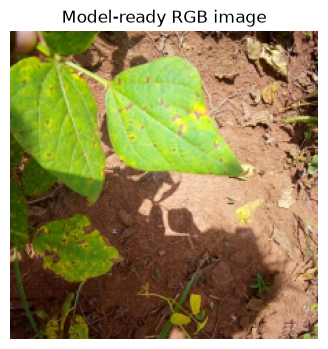

In [21]:
# Step 8.2 — Acceptance tests for ONE image.
processed_example = preprocess_image(dataset["train"][0]["image"])

assert isinstance(processed_example, np.ndarray)
assert processed_example.shape == (224, 224, 3), processed_example.shape
assert processed_example.dtype == np.float32, processed_example.dtype
assert np.isfinite(processed_example).all(), "NaN or Inf values found"
assert 0.0 <= processed_example.min() <= processed_example.max() <= 1.0

print("PASS: correct shape, dtype, and value range")
print("Shape:", processed_example.shape)
print("Dtype:", processed_example.dtype)
print("Min/Max:", processed_example.min(), processed_example.max())

plt.figure(figsize=(4, 4))
plt.imshow(processed_example)
plt.title("Model-ready RGB image")
plt.axis("off")
plt.show()

### Step 8.3 — Compare original and processed images

**🛠️ YOUR TASK**
- Show original and processed images side by side.
- Check if your resizing changed the leaf shape.
- Make sure the processed image is **not** grayscale or black because of incorrect conversion.

**Engineer question:** If your original image is already `500×500`, will resizing to `224×224` change its aspect ratio?

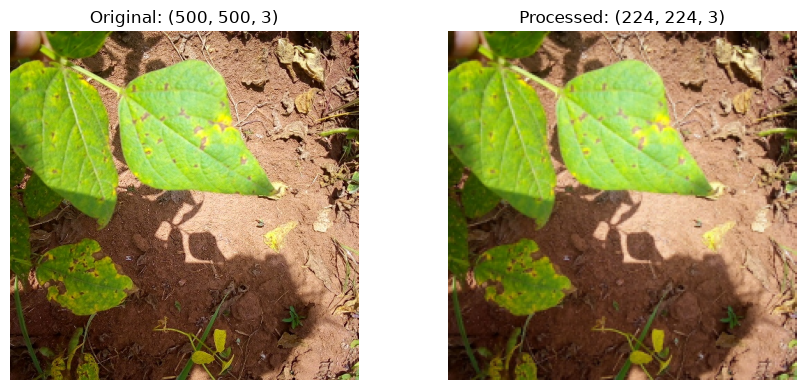

Direct resize preserves all pixels but can change aspect ratio when width and height scale differently.


In [22]:
# Compare the original and processed image.
original_example = np.asarray(dataset["train"][0]["image"].convert("RGB"))
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(original_example); axes[0].set_title(f"Original: {original_example.shape}")
axes[1].imshow(processed_example); axes[1].set_title(f"Processed: {processed_example.shape}")
for axis in axes: axis.axis("off")
plt.tight_layout(); plt.show()
print("Direct resize preserves all pixels but can change aspect ratio when width and height scale differently.")


## 9 — Prepare the three model-ready splits

### Why this step matters
Training code needs consistent `X` (images) and `y` (labels). We must preserve the original splits to avoid data leakage:

- `train`: the model learns from this split.
- `validation`: the developer selects settings and evaluates during development.
- `test`: final held-out evaluation later — **do not tune your preprocessing using test performance**.

For this small dataset, a NumPy array is convenient. It can still use significant memory (float32 RGB images are large), so avoid making unnecessary copies.

### Step 9.1 — Create a function that processes one split

**🛠️ YOUR TASK**

- Loop through all rows in one split.
- Apply **your** `preprocess_image()` function.
- Append each processed image to `X`.
- Append the matching integer class ID to `y`.
- Return `X` and `y` as NumPy arrays.
- Keep the row order unchanged.

**Hints:** `np.stack(images)` and `np.asarray(labels, dtype=np.int64)`.

In [23]:
# Process one split while preserving its row order and labels.
def prepare_split(split_data):
    """Return X and y arrays, in the same order as split_data."""
    images, labels = [], []
    for row in split_data:
        images.append(preprocess_image(row["image"]))
        labels.append(int(row["labels"]))
    X = np.stack(images, axis=0).astype(np.float32)
    y = np.asarray(labels, dtype=np.int64)
    return X, y


### Step 9.2 — Build `X_train`, `X_val`, and `X_test`

**🛠️ YOUR TASK**
- Run the preprocessing function on all three original splits.
- Print the shapes.
- Check that the number of labels equals the number of images.

**Memory note:** This can use about 0.8 GB for the float32 image arrays alone; Colab should usually handle it. If your device runs out of memory, process and save one split at a time, or use a lazy data loader (bonus challenge).

In [24]:
# Run after completing Step 9.1.
X_train, y_train = prepare_split(dataset["train"])
X_val, y_val = prepare_split(dataset["validation"])
X_test, y_test = prepare_split(dataset["test"])

print("X_train, y_train:", X_train.shape, y_train.shape)
print("X_val, y_val:    ", X_val.shape, y_val.shape)
print("X_test, y_test:  ", X_test.shape, y_test.shape)

X_train, y_train: (1034, 224, 224, 3) (1034,)
X_val, y_val:     (133, 224, 224, 3) (133,)
X_test, y_test:   (128, 224, 224, 3) (128,)


### Step 9.3 — Quality checks before export

### Why this step matters
Do not give arrays to the model engineer without checking them. The handoff must have correct dimensions, data types, label values, and split sizes.

**🛠️ YOUR TASK**
- Run the checks below.
- If one test fails, fix the preprocessing instead of deleting the assertion.
- Add one extra test of your own.

In [25]:
# Step 9.3 — Automated acceptance checks (do not remove these).
expected_counts = {"train": 1034, "validation": 133, "test": 128}

for name, X, y in [
    ("train", X_train, y_train),
    ("validation", X_val, y_val),
    ("test", X_test, y_test),
]:
    assert len(X) == len(dataset[name]), f"Wrong {name} image count"
    assert len(X) == expected_counts[name], f"Unexpected number of {name} images"
    assert len(X) == len(y), f"X/y mismatch in {name}"
    assert X.ndim == 4 and X.shape[1:] == (224, 224, 3)
    assert X.dtype == np.float32
    assert np.isfinite(X).all(), f"NaN/Inf values in {name}"
    assert 0 <= float(X.min()) <= float(X.max()) <= 1
    assert set(np.unique(y)).issubset(set(range(len(CLASS_NAMES))))
    assert np.array_equal(y, np.asarray(dataset[name]["labels"])), "Changed label order!"
    print(f"PASS: {name}: {X.shape}, dtype={X.dtype}, range=[{X.min():.3f}, {X.max():.3f}]")

# TODO 9.3 — Add ONE extra test:
# Example: verify all 3 classes are still present in the training split.
assert set(np.unique(y_train)) == set(range(len(CLASS_NAMES))), "Training split must contain every class"
print("PASS: all expected classes are present in the training split.")


PASS: train: (1034, 224, 224, 3), dtype=float32, range=[0.000, 1.000]
PASS: validation: (133, 224, 224, 3), dtype=float32, range=[0.000, 1.000]
PASS: test: (128, 224, 224, 3), dtype=float32, range=[0.000, 1.000]
PASS: all expected classes are present in the training split.


### Step 9.4 — Export your prepared data

### Why this step matters
A project deliverable must be easy for another person to load and use. We will save the processed images, matching labels, and a small metadata file.

**🛠️ YOUR TASK**
- Save `train`, `validation`, and `test` separately as compressed `.npz` files.
- Save the class names and preprocessing choices in `metadata.json`.
- Reload one saved file to check that it works.

**Hint:** `np.savez_compressed(path, X=..., y=...)`, `json.dump(...)`, `np.load(...)`.

In [26]:
# Export all prepared splits and preprocessing metadata.
np.savez_compressed(EXPORT_DIR / "train.npz", X=X_train, y=y_train)
np.savez_compressed(EXPORT_DIR / "validation.npz", X=X_val, y=y_val)
np.savez_compressed(EXPORT_DIR / "test.npz", X=X_test, y=y_test)

metadata = {
    "source": DATASET_ID,
    "class_names": list(CLASS_NAMES),
    "class_to_id": CLASS_TO_ID,
    "target_size": list(TARGET_SIZE),
    "color_order": "RGB",
    "array_layout": "NHWC",
    "dtype": "float32",
    "normalization": "pixel / 255.0",
    "resize_strategy": "direct resize to 224x224 (may change aspect ratio)",
    "splits": {name: len(dataset[name]) for name in dataset.keys()},
    "augmentation_in_saved_arrays": False,
    "filters_applied": False,
}
with open(EXPORT_DIR / "metadata.json", "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2)

with np.load(EXPORT_DIR / "train.npz") as saved:
    print("Reloaded train shapes:", saved["X"].shape, saved["y"].shape)


Reloaded train shapes: (1034, 224, 224, 3) (1034,)


### Step 9.5 — Show your handoff is ready

**🛠️ YOUR TASK**

- Show a small gallery of **processed** images with their class names.
- Print final array shapes.
- Print the names and sizes of the files in `beans_model_ready/`.
- Do not train a model. Your job stops at a validated dataset.

**Hint:** For the gallery, `X_train` is already RGB with values in `[0,1]`, so you can use `plt.imshow(X_train[i])`.

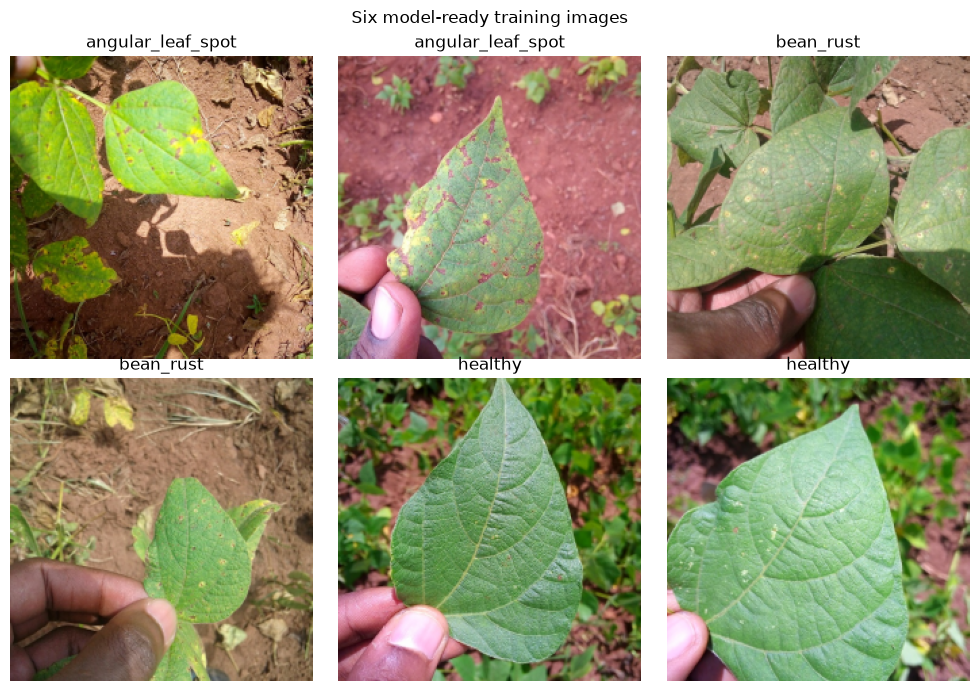

Final array shapes:
Train: (1034, 224, 224, 3) (1034,)
Validation: (133, 224, 224, 3) (133,)
Test: (128, 224, 224, 3) (128,)

Exported files:
metadata.json             0.00 MB
test.npz                 24.39 MB
train.npz               196.85 MB
validation.npz           25.28 MB


In [27]:
# Display six processed training examples with their class names.
sample_indices = np.linspace(0, len(X_train) - 1, 6, dtype=int)
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for axis, index in zip(axes.flat, sample_indices):
    axis.imshow(X_train[index])
    axis.set_title(CLASS_NAMES[int(y_train[index])])
    axis.axis("off")
plt.suptitle("Six model-ready training images")
plt.tight_layout(); plt.show()

print("Final array shapes:")
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)
print("\nExported files:")
for path in sorted(EXPORT_DIR.glob("*")):
    print(f"{path.name:20s}  {path.stat().st_size / (1024**2):8.2f} MB")


### Step 9.6 — Check the image layout for the future framework

### Why this step matters
We saved each image as **H × W × C** (height, width, channels). That is a good model-ready data format, but different deep-learning libraries may want different axis orders.

- **TensorFlow / Keras** commonly uses **NHWC**: `(batch, height, width, channels)` — the current `X_train` layout.
- **PyTorch** commonly uses **NCHW**: `(batch, channels, height, width)` — you may need a transpose later.

**🛠️ YOUR TASK**
- Record the format of your saved arrays.
- State which simple axis operation you would use if the next engineer uses PyTorch.
- Do **not** train the CNN in this assignment.


In [28]:
# NHWC is the saved layout; transpose axes for PyTorch's NCHW convention.
print("Saved array layout (NHWC):", X_train.shape)
X_train_nchw = np.transpose(X_train, (0, 3, 1, 2))
print("PyTorch-style view (NCHW):", X_train_nchw.shape)


Saved array layout (NHWC): (1034, 224, 224, 3)
PyTorch-style view (NCHW): (1034, 3, 224, 224)


## 10 — Final engineering handoff

### What the next engineer should receive

Your final folder should contain these files:

```text
beans_model_ready/
├── train.npz       # X: (1034,224,224,3), y: (1034,)
├── validation.npz  # X: (133,224,224,3),  y: (133,)
├── test.npz        # X: (128,224,224,3),  y: (128,)
└── metadata.json   # class names and preprocessing choices
```
**No model training is required in this assignment.**